# Latihan

## STAT MODELS

Bagian ini membahas pemodelan statistika menggunakan pustaka `statsmodels`. Di sini, kita melakukan analisis regresi linear berganda untuk memahami hubungan antara variabel independen dan variabel dependen secara matematis.

In [18]:
#Import Library
import numpy as np
import pandas as pd
import statsmodels.api as sm

# Membuat DataFrame dari data yang diberikan
data = {
'Partisipan': np.arange(1, 11),
'PMakan': [50, 40, 60, 55, 45, 65, 70, 75, 80, 90],
'PTranspor': [20, 25, 30, 35, 40, 50, 55, 60, 65, 70],
'BB': [60, 55, 65, 70, 62, 75, 80, 85, 90, 95]}

df = pd.DataFrame(data)

# Memisahkan variabel independen dan dependen
X = df[['PMakan', 'PTranspor']]
y = df['BB']

X = sm.add_constant(X) # Menambahkan kolom konstanta untuk intercept

model = sm.OLS(y, X) # Membangun model regresi
results = model.fit()

print(results.summary()) # Menampilkan hasil

                            OLS Regression Results                            
Dep. Variable:                     BB   R-squared:                       0.985
Model:                            OLS   Adj. R-squared:                  0.981
Method:                 Least Squares   F-statistic:                     234.6
Date:                Tue, 13 Oct 2026   Prob (F-statistic):           3.85e-07
Time:                        03:42:21   Log-Likelihood:                -18.626
No. Observations:                  10   AIC:                             43.25
Df Residuals:                       7   BIC:                             44.16
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         26.9870      2.879      9.374      0.0

## VISUAL 3 DIMENSI

Bagian ini menyajikan visualisasi tiga dimensi (3D) interaktif menggunakan Plotly. Melalui visualisasi ini, kita dapat melihat posisi data aktual serta bagaimana bidang regresi terbentuk berdasarkan model yang telah diestimasi sebelumnya.

In [19]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import plotly.graph_objects as go

data = {
    "Partisipan": np.arange(1, 11),
    "Peng Makanan": [50, 40, 60, 55, 45, 65, 70, 75, 80, 90],
    "Peng Transportasi": [20, 25, 30, 35, 40, 50, 55, 60, 65, 70],
    "Berat Badan": [60, 55, 65, 70, 62, 75, 80, 85, 90, 95]
}
df = pd.DataFrame(data)

# Variabel independen
X = df[["Peng Makanan", "Peng Transportasi"]]
# Variabel dependen
y = df["Berat Badan"]

# 4. MENAMBAHKAN INTERCEPT
X_model = sm.add_constant(X)

# 5. ESTIMASI MODEL OLS
model = sm.OLS(y, X_model)
results = model.fit()

# 6. MENAMPILKAN RINGKASAN HASIL REGRESI
print("\n")
print("=" * 70)
print(" HASIL REGRESI LINEAR BERGANDA")
print("=" * 70)
print(results.summary())

# 7. MENGAMBIL KOEFISIEN REGRESI
intercept = results.params["const"]
coef_makanan = results.params["Peng Makanan"]
coef_transportasi = results.params["Peng Transportasi"]
r_squared = results.rsquared
adjusted_r_squared = results.rsquared_adj

# 8. MEMBUAT PERSAMAAN REGRESI
persamaan = (
    f"Ŷ = {intercept:.3f}"
    f" + ({coef_makanan:.3f}) X1"
    f" + ({coef_transportasi:.3f}) X2"
)
print("\n")
print("=" * 70)
print(" PERSAMAAN REGRESI")
print("=" * 70)
print(persamaan)
print(f"\nR2 = {r_squared:.4f}")
print(f"Adjusted R2 = {adjusted_r_squared:.4f}")

# 9. MENGHITUNG NILAI PREDIKSI
df["Prediksi"] = results.predict(X_model)
print("\n")
print("=" * 70)
print(" DATA AKTUAL & PREDIKSI")
print("=" * 70)
print(
    df[["Partisipan", "Peng Makanan", "Peng Transportasi", "Berat Badan", "Prediksi"]].round(2)
)

# 10. MEMBUAT GRID UNTUK BIDANG REGRESI
x1 = np.linspace(
    df["Peng Makanan"].min(),
    df["Peng Makanan"].max(),
    40
)
x2 = np.linspace(
    df["Peng Transportasi"].min(),
    df["Peng Transportasi"].max(),
    40
)
X1, X2 = np.meshgrid(x1, x2)

# 11. MENGHITUNG NILAI Y PADA BIDANG REGRESI
Y = (intercept + coef_makanan * X1 + coef_transportasi * X2)

# 12. MEMBUAT FIGURE 3D
fig = go.Figure()

# 13. MENAMPILKAN DATA AKTUAL
fig.add_trace(
    go.Scatter3d(
        x=df["Peng Makanan"],
        y=df["Peng Transportasi"],
        z=df["Berat Badan"],
        mode="markers",
        marker=dict(
            size=7,
            color="red",
            opacity=0.9
        ),
        name="Data Aktual",
        text=[
            f"Partisipan {p}"
            for p in df["Partisipan"]
        ],
        hovertemplate=(
            "<b>%{text}</b><br>"
            "Peng. Makanan: %{x}<br>"
            "Peng. Transportasi: %{y}<br>"
            "Berat Badan: %{z}"
            "<extra></extra>"
        )
    )
)

# 14. MENAMPILKAN BIDANG REGRESI
fig.add_trace(
    go.Surface(
        x=X1, y=X2, z=Y,
        opacity=0.60,
        colorscale="Viridis",
        name="Regression Plane",
        hovertemplate=(
            "Peng. Makanan: %{x:.2f}<br>"
            "Peng. Transportasi: %{y:.2f}<br>"
            "Prediksi Y: %{z:.2f}"
            "<extra></extra>"
        )
    )
)

# 15. MENGATUR TAMPILAN GRAFIK
fig.update_layout(
    title={
        "text": (
            "REGRESI LINEAR BERGANDA 3D"
            "<br>"
            f"<sup>{persamaan} | "
            f"R2 = {r_squared:.3f}</sup>"
        ), "x": 0.5
    },
    scene={
        "xaxis": {"title": "Pengeluaran Makanan (X1)"},
        "yaxis": {"title": "Pengeluaran Transportasi (X2)"},
        "zaxis": {"title": "Berat Badan (Y)"}
    },
    width=1000,
    height=750,
    margin={
        "l": 0, "r": 0, "b": 0, "t": 100
    },
    legend={"x": 0.02, "y": 0.98}
)

# 16. MENAMPILKAN GRAFIK
fig.show()



 HASIL REGRESI LINEAR BERGANDA
                            OLS Regression Results                            
Dep. Variable:            Berat Badan   R-squared:                       0.985
Model:                            OLS   Adj. R-squared:                  0.981
Method:                 Least Squares   F-statistic:                     234.6
Date:                Tue, 13 Oct 2026   Prob (F-statistic):           3.85e-07
Time:                        03:42:21   Log-Likelihood:                -18.626
No. Observations:                  10   AIC:                             43.25
Df Residuals:                       7   BIC:                             44.16
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const

# REGRESI BERGANDA

## Indikator Variabel

Di bagian ini, kita mendefinisikan indikator variabel yang akan dianalisis, yaitu hubungan antara Indeks Pembangunan Manusia (IPM) sebagai variabel dependen, serta belanja fungsi (Pendidikan, Kesehatan, dan Infrastruktur) sebagai variabel independen untuk wilayah Kota Pagar Alam.

### Import & Ambil Data Kota Pagar Alam

Langkah ini bertujuan untuk memuat keseluruhan dataset fiskal dan menyaringnya khusus untuk wilayah Kota Pagar Alam, serta memilih variabel-variabel relevan yang akan digunakan dalam analisis regresi.

### Regresi berganda

Di sini kita membangun model Ordinary Least Squares (OLS) untuk mengestimasi dampak pengeluaran belanja daerah secara simultan dan parsial terhadap pencapaian IPM di Kota Pagar Alam.

In [21]:
# Variabel independen (X) dan dependen (Y)
X = df[["Belanja Pendidikan", "Belanja Kesehatan", "Belanja Infrastruktur"]]
y = df["IPM"]

# Menambahkan intercept
X_model = sm.add_constant(X)

# Estimasi OLS
model = sm.OLS(y, X_model)
results = model.fit()

print("=" * 70)
print(" HASIL REGRESI LINEAR BERGANDA - KOTA PAGAR ALAM")
print("=" * 70)
print(results.summary())

# Ambil koefisien
intercept = results.params["const"]
b1 = results.params["Belanja Pendidikan"]
b2 = results.params["Belanja Kesehatan"]
b3 = results.params["Belanja Infrastruktur"]
r_squared = results.rsquared
adjusted_r_squared = results.rsquared_adj

# Persamaan regresi
persamaan = (
    f"Ŷ = {intercept:.3f}"
    f" + ({b1:.3f}) X1"
    f" + ({b2:.3f}) X2"
    f" + ({b3:.3f}) X3"
)

print("\n" + "=" * 70)
print(" PERSAMAAN REGRESI")
print("=" * 70)
print(persamaan)
print(f"\nR2 = {r_squared:.4f}")
print(f"Adjusted R2 = {adjusted_r_squared:.4f}")

# Nilai prediksi
df["Prediksi"] = results.predict(X_model)
print("\n" + "=" * 70)
print(" DATA AKTUAL & PREDIKSI")
print("=" * 70)
print(df.round(2))

 HASIL REGRESI LINEAR BERGANDA - KOTA PAGAR ALAM
                            OLS Regression Results                            
Dep. Variable:                    IPM   R-squared:                       0.495
Model:                            OLS   Adj. R-squared:                  0.279
Method:                 Least Squares   F-statistic:                     2.288
Date:                Tue, 13 Oct 2026   Prob (F-statistic):              0.166
Time:                        03:42:21   Log-Likelihood:                -32.129
No. Observations:                  11   AIC:                             72.26
Df Residuals:                       7   BIC:                             73.85
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------

### Visualisasi 3D

Bagian ini menyajikan representasi grafis 3D dari hasil pemodelan. Mengingat kita memiliki tiga variabel bebas sementara dimensi grafik terbatas pada 3D, salah satu variabel bebas (Belanja Infrastruktur) akan dikunci pada nilai rata-ratanya atau direpresentasikan lewat warna titik data.

#### 3D Dasar

Bagian ini menyajikan model visualisasi 3D dasar interaktif **menggunakan pustaka Plotly**. Di sini, variabel ketiga (Belanja Infrastruktur atau X3) **dikunci pada satu nilai tunggal (rata-rata)** untuk membentuk bidang datar proyeksi regresi. Pendekatan ini berguna untuk melihat bentuk hubungan murni antara dua variabel belanja utama terhadap IPM tanpa gangguan fluktuasi variabel ketiga.

**Cara Membaca Visualisasi Ini:**
* Arahkan kursor Anda ke area grafik. Anda akan melihat sebuah bidang datar (*regression plane*) berwarna gradasi hijau-kuning. Bidang ini menggambarkan skenario teoritis ketika nilai Belanja Infrastruktur ($X_3$) dipatok tetap pada rata-ratanya (~137,0).
* Titik-titik merah di luar bidang tersebut adalah data aktual tahunan IPM Kota Pagar Alam.
* Jika titik merah berada **di atas** bidang, artinya realisasi IPM pada tahun tersebut lebih tinggi daripada perkiraan model regresi. Sebaliknya, jika titik berada **di bawah** bidang, realisasi IPM lebih rendah dari prediksi teoritis.

In [26]:
# Grid untuk bidang regresi (X1 dan X2)
x1 = np.linspace(df["Belanja Pendidikan"].min(), df["Belanja Pendidikan"].max(), 40)
x2 = np.linspace(df["Belanja Kesehatan"].min(), df["Belanja Kesehatan"].max(), 40)
X1, X2 = np.meshgrid(x1, x2)

# X3 dikunci di rata-rata
x3_rata = df["Belanja Infrastruktur"].mean()

# Nilai Y pada bidang regresi
Y = intercept + b1 * X1 + b2 * X2 + b3 * x3_rata

fig = go.Figure()

# Data aktual
fig.add_trace(
    go.Scatter3d(
        x=df["Belanja Pendidikan"],
        y=df["Belanja Kesehatan"],
        z=df["IPM"],
        mode="markers",
        marker=dict(size=7, color="red", opacity=0.9),
        name="Data Aktual",
        text=[f"Tahun {t}" for t in df["Tahun"]],
        hovertemplate=(
            "<b>%{text}</b><br>"
            "Belanja Pendidikan: %{x}<br>"
            "Belanja Kesehatan: %{y}<br>"
            "IPM: %{z}"
            "<extra></extra>"
        )
    )
)

# Bidang regresi
fig.add_trace(
    go.Surface(
        x=X1, y=X2, z=Y,
        opacity=0.60,
        colorscale="Viridis",
        name="Bidang Regresi",
        hovertemplate=(
            "Belanja Pendidikan: %{x:.2f}<br>"
            "Belanja Kesehatan: %{y:.2f}<br>"
            "Prediksi IPM: %{z:.2f}"
            "<extra></extra>"
        )
    )
)

fig.update_layout(
    title={
        "text": (
            "REGRESI LINEAR BERGANDA 3D - KOTA PAGAR ALAM"
            "<br>"
            f"<sup>{persamaan} | R2 = {r_squared:.3f}<br>"
            f"(X3 dikunci di rata-rata = {x3_rata:.1f})</sup>"
        ), "x": 0.5
    },
    scene={
        "xaxis": {"title": "Belanja Pendidikan (X1)"},
        "yaxis": {"title": "Belanja Kesehatan (X2)"},
        "zaxis": {"title": "IPM (Y)"}
    },
    width=1000,
    height=750,
    margin={"l": 0, "r": 0, "b": 0, "t": 120},
    legend={"x": 0.02, "y": 0.98}
)

fig.show()

#### 3D Matplotlib

Bagian ini menggunakan pustaka Matplotlib untuk menghasilkan grafik 3D yang bersifat **statis (tidak dapat diputar secara interaktif)** namun sangat cocok untuk kebutuhan cetak atau dokumen fisik. Perbedaan utamanya adalah **penggunaan gradasi warna pada titik data aktual** untuk merepresentasikan nilai riil dari Belanja Infrastruktur (X3), sehingga kita bisa melihat sebaran asli data di luar rata-ratanya.

**Cara Membaca Visualisasi Ini:**
* Sumbu tegak melambangkan IPM ($Y$). Sumbu datar melambangkan Belanja Pendidikan ($X_1$) dan Kesehatan ($X_2$).
* Indikator kunci di sini adalah **skala warna (colorbar) di sisi kanan**: warna gelap (biru/ungu tua) mewakili anggaran infrastruktur yang rendah, sedangkan warna terang (kuning) mewakili anggaran infrastruktur yang sangat tinggi.
* Perhatikan bahwa titik-titik berwarna gelap cenderung berada di posisi atas (IPM tinggi), yang secara visual menjelaskan mengapa koefisien pengaruh Belanja Infrastruktur bernilai negatif pada model ini.

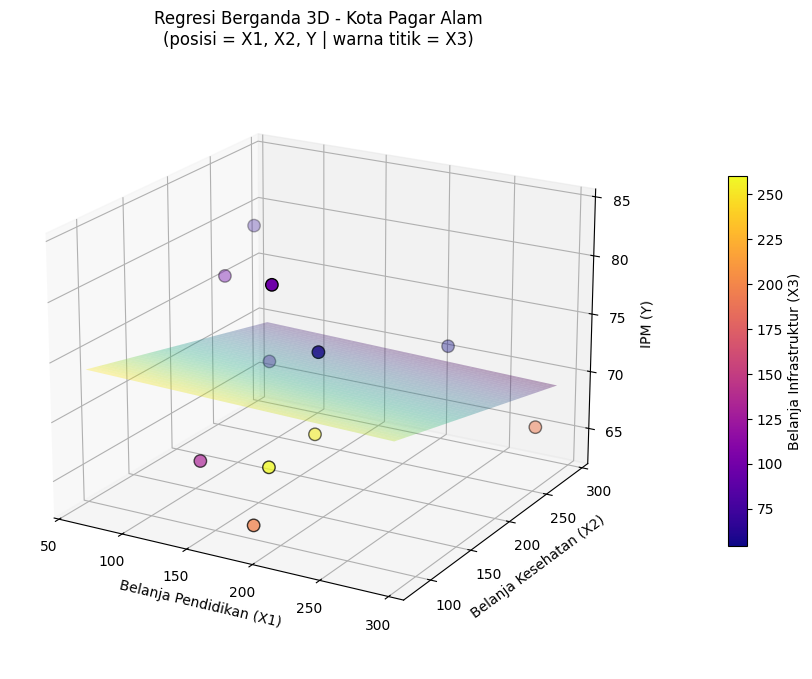

In [22]:
import numpy as np
import matplotlib.pyplot as plt

# Grid untuk bidang regresi (X1 dan X2)
x1 = np.linspace(df["Belanja Pendidikan"].min(), df["Belanja Pendidikan"].max(), 40)
x2 = np.linspace(df["Belanja Kesehatan"].min(), df["Belanja Kesehatan"].max(), 40)
X1, X2 = np.meshgrid(x1, x2)

# X3 dikunci di rata-rata (khusus untuk menggambar bidang)
x3_rata = df["Belanja Infrastruktur"].mean()
Y = intercept + b1 * X1 + b2 * X2 + b3 * x3_rata

fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(111, projection="3d")

# Bidang regresi
ax.plot_surface(X1, X2, Y, alpha=0.35, cmap="viridis")

# Data aktual: posisi = X1, X2, Y | warna = X3
sc = ax.scatter(
    df["Belanja Pendidikan"],
    df["Belanja Kesehatan"],
    df["IPM"],
    c=df["Belanja Infrastruktur"],
    cmap="plasma", s=80, edgecolor="black"
)

# Colorbar untuk X3
cbar = fig.colorbar(sc, ax=ax, shrink=0.6, pad=0.12)
cbar.set_label("Belanja Infrastruktur (X3)")

ax.set_xlabel("Belanja Pendidikan (X1)")
ax.set_ylabel("Belanja Kesehatan (X2)")
ax.set_zlabel("IPM (Y)")
ax.set_title("Regresi Berganda 3D - Kota Pagar Alam\n(posisi = X1, X2, Y | warna titik = X3)")
ax.view_init(elev=20, azim=-60)

plt.savefig("regresi_3d.png", dpi=200, bbox_inches="tight")
plt.show()

#### 3D Plotly

Bagian ini merupakan **metode paling lengkap dan interaktif** yang menggabungkan keunggulan kedua metode sebelumnya. Grafik ini dapat diputar, diperbesar, dan memiliki fitur *hover* dinamis. Di sini, bidang prediksi tetap menggunakan asumsi rata-rata X3, tetapi tiap titik data aktual diwarnai berdasarkan nilai riil variabel X3-nya menggunakan skala warna *Plasma*, memberikan visualisasi 4 dimensi (tiga dimensi ruang + satu dimensi warna) yang interaktif.

**Cara Membaca Visualisasi Ini:**
* Anda dapat klik dan seret tetikus (mouse) untuk memutar grafik serta mengamati letak koordinat dari berbagai sudut pandang.
* Warna tiap titik data aktual di sini melambangkan besaran anggaran Belanja Infrastruktur menggunakan skala warna *Plasma* (sesuai colorbar di sebelah kanan).
* Saat Anda menggeser kursor ke sebuah titik data, kotak informasi (*tooltip*) akan muncul menampilkan rincian data aktual tahun tersebut secara presisi (Tahun, nilai riil Belanja Pendidikan, Belanja Kesehatan, Belanja Infrastruktur, dan realisasi IPM), memudahkan Anda memvalidasi anomali data secara langsung.

In [24]:
import plotly.graph_objects as go

# Grid bidang regresi (X1 dan X2), X3 dikunci di rata-rata
x1 = np.linspace(df["Belanja Pendidikan"].min(), df["Belanja Pendidikan"].max(), 40)
x2 = np.linspace(df["Belanja Kesehatan"].min(), df["Belanja Kesehatan"].max(), 40)
X1, X2 = np.meshgrid(x1, x2)
x3_rata = df["Belanja Infrastruktur"].mean()
Y = intercept + b1 * X1 + b2 * X2 + b3 * x3_rata

fig = go.Figure()

# Data aktual: posisi = X1, X2, Y | warna = X3
fig.add_trace(
    go.Scatter3d(
        x=df["Belanja Pendidikan"],
        y=df["Belanja Kesehatan"],
        z=df["IPM"],
        mode="markers",
        marker=dict(
            size=8,
            color=df["Belanja Infrastruktur"],
            colorscale="Plasma",
            showscale=True,
            colorbar=dict(title="Belanja Infrastruktur (X3)", x=1.0),
            line=dict(color="black", width=1)
        ),
        name="Data Aktual",
        text=[f"Tahun {t}" for t in df["Tahun"]],
        customdata=df["Belanja Infrastruktur"],
        hovertemplate=(
            "<b>%{text}</b><br>"
            "Belanja Pendidikan (X1): %{x}<br>"
            "Belanja Kesehatan (X2): %{y}<br>"
            "Belanja Infrastruktur (X3): %{customdata}<br>"
            "IPM: %{z}"
            "<extra></extra>"
        )
    )
)

# Bidang regresi
fig.add_trace(
    go.Surface(
        x=X1, y=X2, z=Y,
        opacity=0.50,
        colorscale="Viridis",
        showscale=False,
        name="Bidang Regresi",
        hovertemplate=(
            "Belanja Pendidikan: %{x:.2f}<br>"
            "Belanja Kesehatan: %{y:.2f}<br>"
            "Prediksi IPM: %{z:.2f}"
            "<extra></extra>"
        )
    )
)

fig.update_layout(
    title={
        "text": (
            "REGRESI LINEAR BERGANDA 3D - KOTA PAGAR ALAM"
            "<br>"
            f"<sup>{persamaan} | R2 = {r_squared:.3f}<br>"
            f"(warna titik = X3 | bidang dihitung dengan X3 = rata-rata {x3_rata:.1f})</sup>"
        ), "x": 0.5
    },
    scene={
        "xaxis": {"title": "Belanja Pendidikan (X1)"},
        "yaxis": {"title": "Belanja Kesehatan (X2)"},
        "zaxis": {"title": "IPM (Y)"}
    },
    width=1000,
    height=750,
    margin={"l": 0, "r": 0, "b": 0, "t": 120},
    legend={"x": 0.02, "y": 0.98}
)

fig.show()

# Simpan versi interaktif sebagai file HTML
fig.write_html("regresi_3d_interaktif.html")

### Interpretasi
Persamaan regresi:

$$\hat{Y} = 84,858 - 0,003 X_1 - 0,022 X_2 - 0,064 X_3$$

#### 1. Uji F (Simultan)
* **F-hitung = 2,288** dengan **Prob (F-statistic) = 0,166** (lebih besar dari 0,05).
* **Kesimpulan:** Secara bersama-sama (simultan), belanja pendidikan ($X_1$), kesehatan ($X_2$), dan infrastruktur ($X_3$) belum memiliki pengaruh yang signifikan secara statistik terhadap IPM Kota Pagar Alam pada taraf signifikansi 5%.

#### 2. Uji t (Parsial)
* **Belanja Pendidikan ($X_1$):** Koefisien $-0,003$ | p-value $0,924$ &rarr; **Tidak Signifikan**.
* **Belanja Kesehatan ($X_2$):** Koefisien $-0,022$ | p-value $0,379$ &rarr; **Tidak Signifikan**.
* **Belanja Infrastruktur ($X_3$):** Koefisien $-0,064$ | p-value $0,041$ &rarr; **Signifikan** (berarah negatif).

> *Catatan penting:* Koefisien negatif pada Belanja Infrastruktur ini berlawanan dengan teori umum ekonomi publik. Hal ini bisa terjadi karena adanya jeda waktu (*time-lag*) di mana dampak pembangunan infrastruktur terhadap peningkatan IPM baru terasa beberapa tahun kemudian, atau akibat keterbatasan data historis yang hanya mencakup 11 observasi.

#### 3. Koefisien Determinasi
* **$R^2 = 0,495$**: Model mampu menjelaskan sekitar 49,5% variasi IPM di Kota Pagar Alam, sedangkan 50,5% sisanya dipengaruhi oleh faktor-faktor lain di luar model.
* **Adjusted $R^2 = 0,279$**: Koreksi nilai determinasi yang menunjukkan daya prediksi model tergolong lemah setelah disesuaikan dengan sedikitnya jumlah data.

#### 4. Kesimpulan Visualisasi 3D
Secara keseluruhan, visualisasi 3D mengonfirmasi temuan statistik kita:
* Bidang prediksi yang landai menunjukkan pengaruh minim dari pengeluaran pendidikan dan kesehatan.
* Gradasi warna titik-titik aktual di ruang 3D mempermudah kita melihat pola sebaran data riil variabel Belanja Infrastruktur ($X_3$) yang memiliki pengaruh signifikan secara parsial terhadap naik-turunnya nilai IPM di Kota Pagar Alam.